# 07 — Accuracy vs Cost Pareto Efficiency Frontiers

Xác định các mô hình không bị thống trị trên không gian 2D: MAE vs Latency suy luận (ms/origin) và MAE vs Thời gian huấn luyện (giây).

### Project Guardrails & Execution Baseline:
- **Protocol Căn cứ:** `training_forecasting_evaluation_protocol_v1_0_21.md` và `spec_module_result_analysis_v2.md`
- **Zero Final Test Access Rule:** Chỉ nạp dữ liệu Validation (724 origins, 2018-05-01 đến 2020-04-23, H=7).
- **Purged Metrics Integrity:** Tuyệt đối không tính hoặc hiển thị CR-MAE@7, CR-Bias@7, RainDay-MAE, hay Bias.
- **Descriptive Cost Principle:** Số liệu tài nguyên chỉ dùng mô tả (PROP-07), không dùng để xếp hạng mô hình.


In [1]:
# Bootstrap root directory
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

ROOT_DIR = Path.cwd()
while not (ROOT_DIR / 'src').exists() and ROOT_DIR != ROOT_DIR.parent:
    ROOT_DIR = ROOT_DIR.parent
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))


PARETO FRONTIER: MAE vs Latency


,scenario_id,model,family,latency_ms_per_origin,MAE,RMSE
0,SC-14,lr_direct_F2,Tabular ML Direct,0.001381,3.354200,6.635300
1,SC-13,lr_direct_F1,Tabular ML Direct,0.002762,3.334200,6.654300
2,SC-44,logistic_linear_stratA_F3,Two-Stage Hurdle,0.006906,3.334091,6.709963
3,SC-42,logistic_linear_stratA_F1,Two-Stage Hurdle,0.008287,3.318662,6.690733
4,SC-33,xgboost_tweedie_F1,Tabular ML Tweedie,0.012431,3.169500,6.642400
5,SC-35,xgboost_tweedie_F3,Tabular ML Tweedie,0.013812,3.168300,6.643500
6,SC-34,xgboost_tweedie_F2,Tabular ML Tweedie,0.016989,3.156500,6.631800
7,SC-30,lightgbm_tweedie_F2,Tabular ML Tweedie,0.021271,3.148500,6.687300



PARETO FRONTIER: MAE vs Training Time


,scenario_id,model,family,training_time_sec,MAE,RMSE
0,SC-09,TSB,Intermittent Demand,0.0000,3.680000,7.166200
1,SC-13,lr_direct_F1,Tabular ML Direct,0.0850,3.334200,6.654300
2,SC-44,logistic_linear_stratA_F3,Two-Stage Hurdle,0.6800,3.334091,6.709963
3,SC-42,logistic_linear_stratA_F1,Two-Stage Hurdle,0.7100,3.318662,6.690733
4,SC-28,lightgbm_tweedie_F0,Tabular ML Tweedie,1.3964,3.237700,6.742800
5,SC-31,lightgbm_tweedie_F3,Tabular ML Tweedie,1.7009,3.193900,6.713100
6,SC-33,xgboost_tweedie_F1,Tabular ML Tweedie,1.7334,3.169500,6.642400
7,SC-35,xgboost_tweedie_F3,Tabular ML Tweedie,2.1342,3.168300,6.643500
8,SC-34,xgboost_tweedie_F2,Tabular ML Tweedie,2.3118,3.156500,6.631800
9,SC-30,lightgbm_tweedie_F2,Tabular ML Tweedie,5.4429,3.148500,6.687300


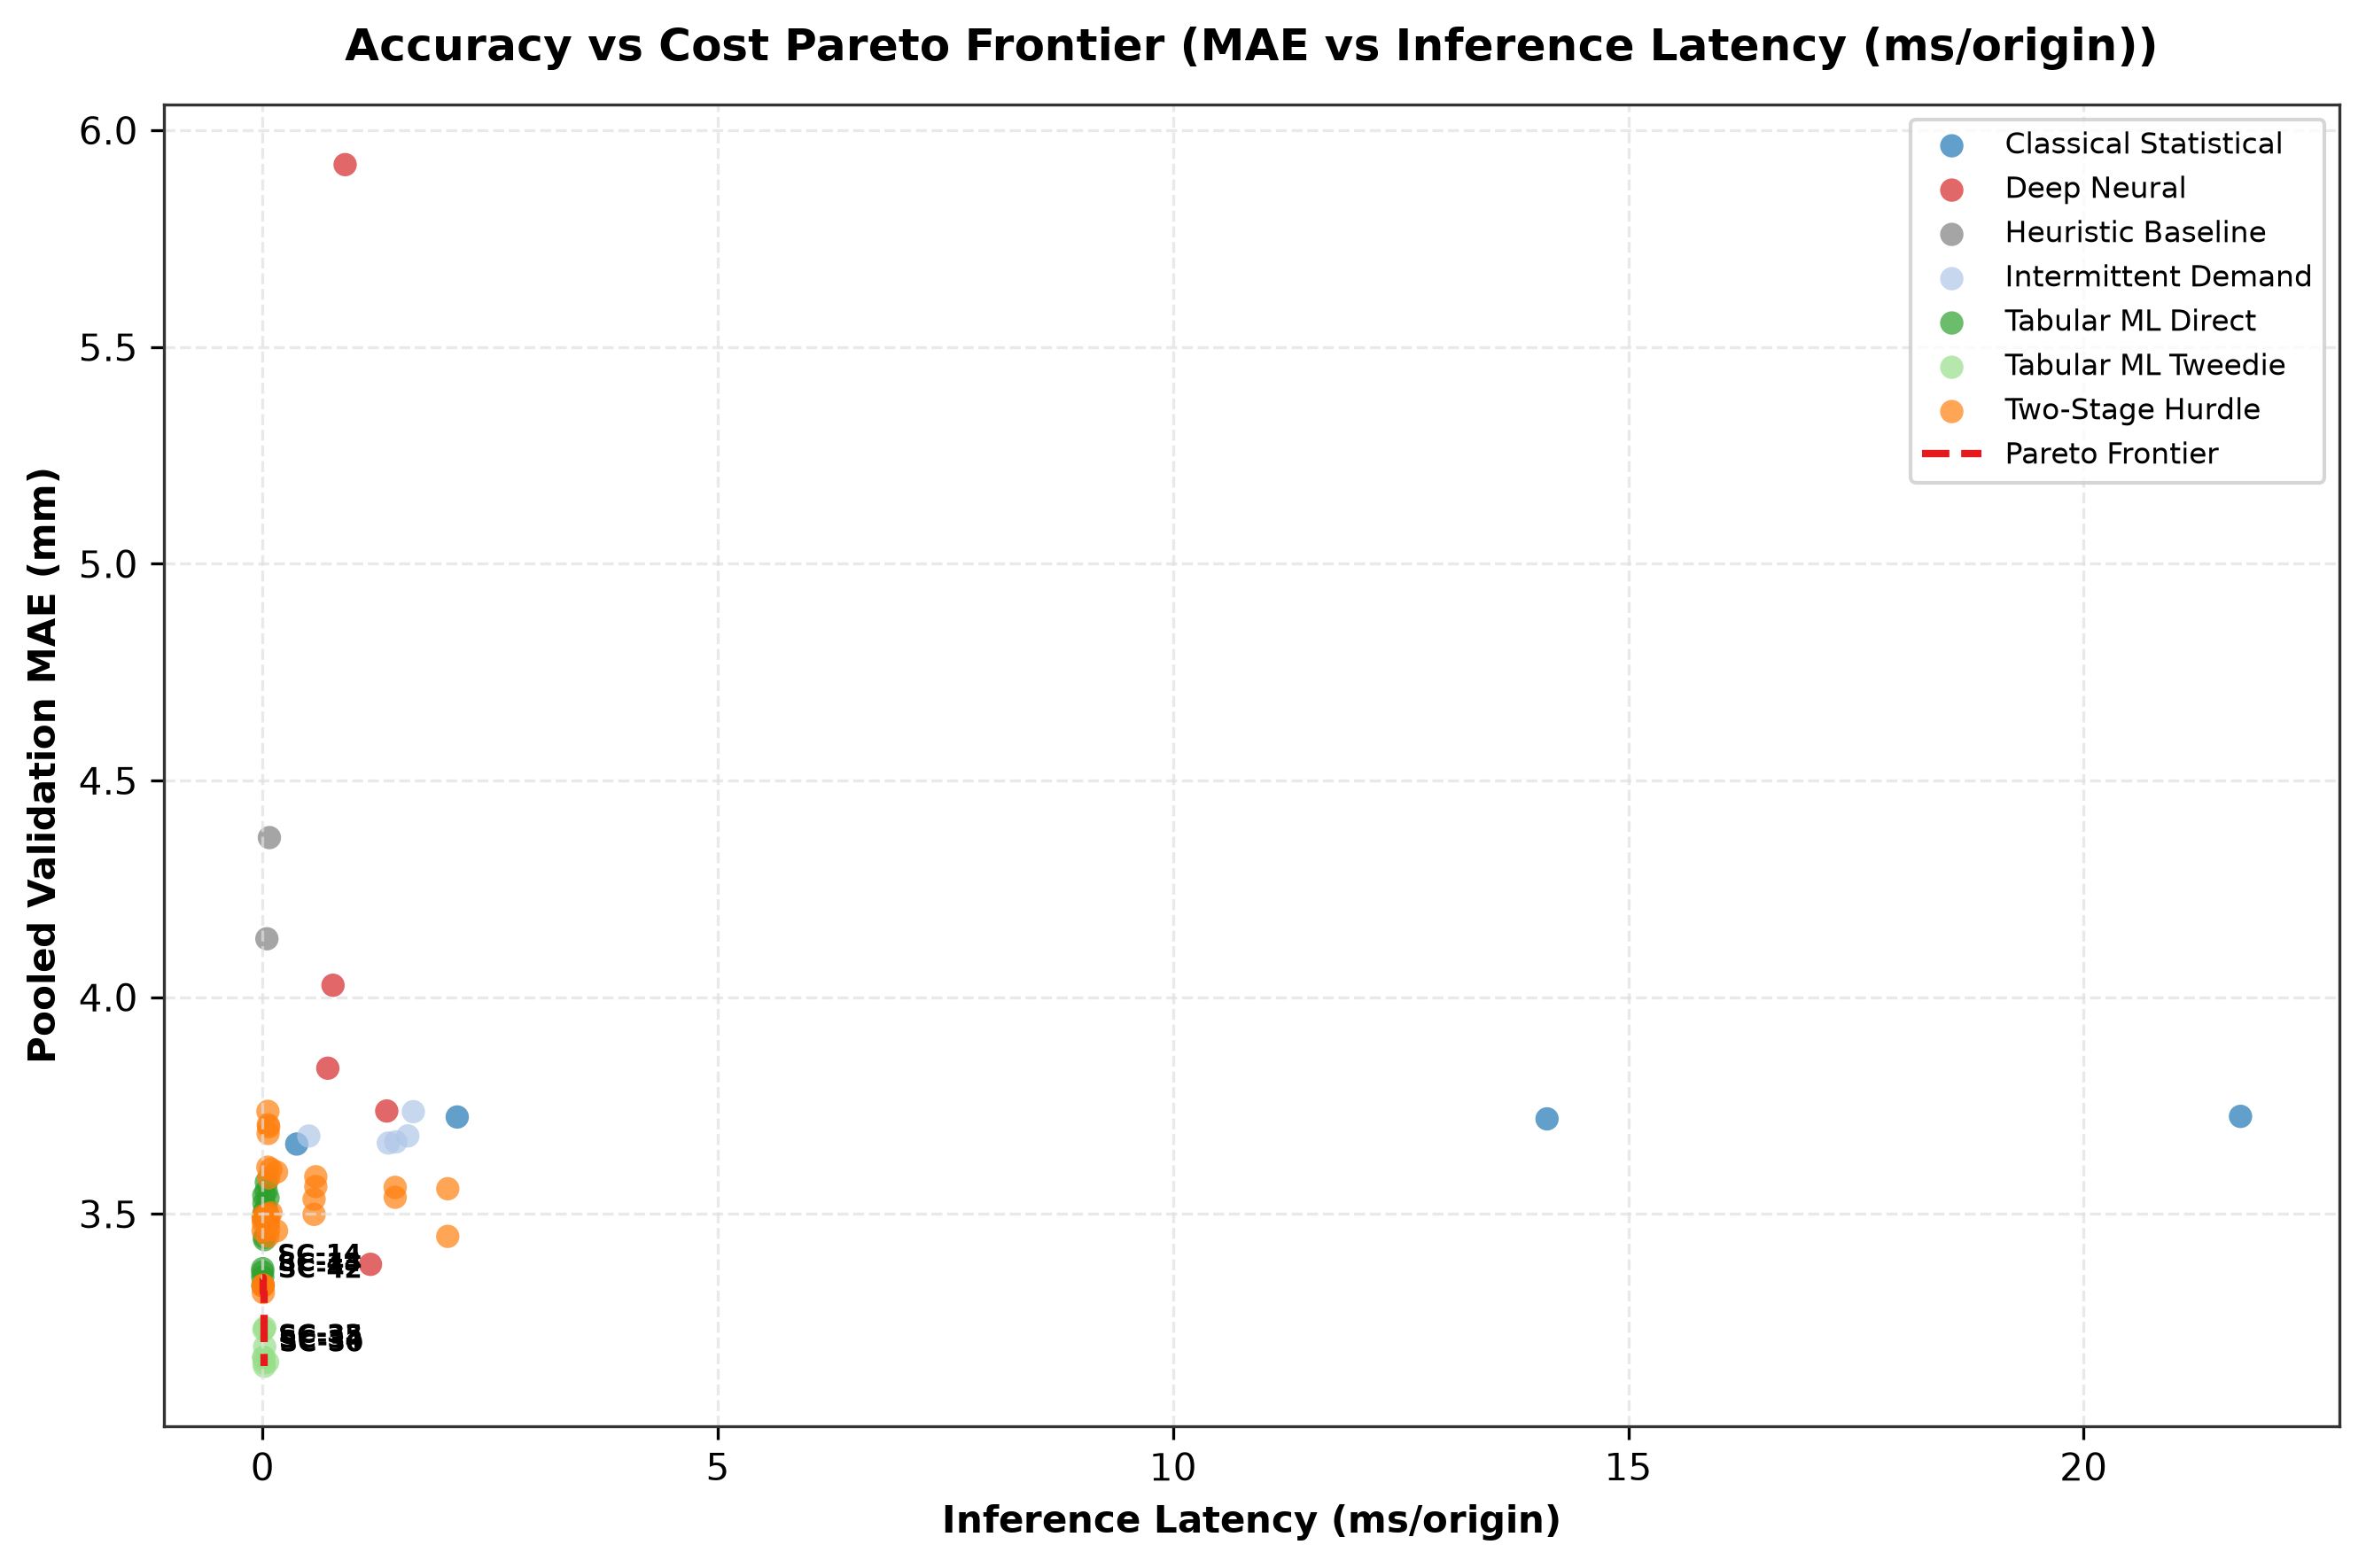

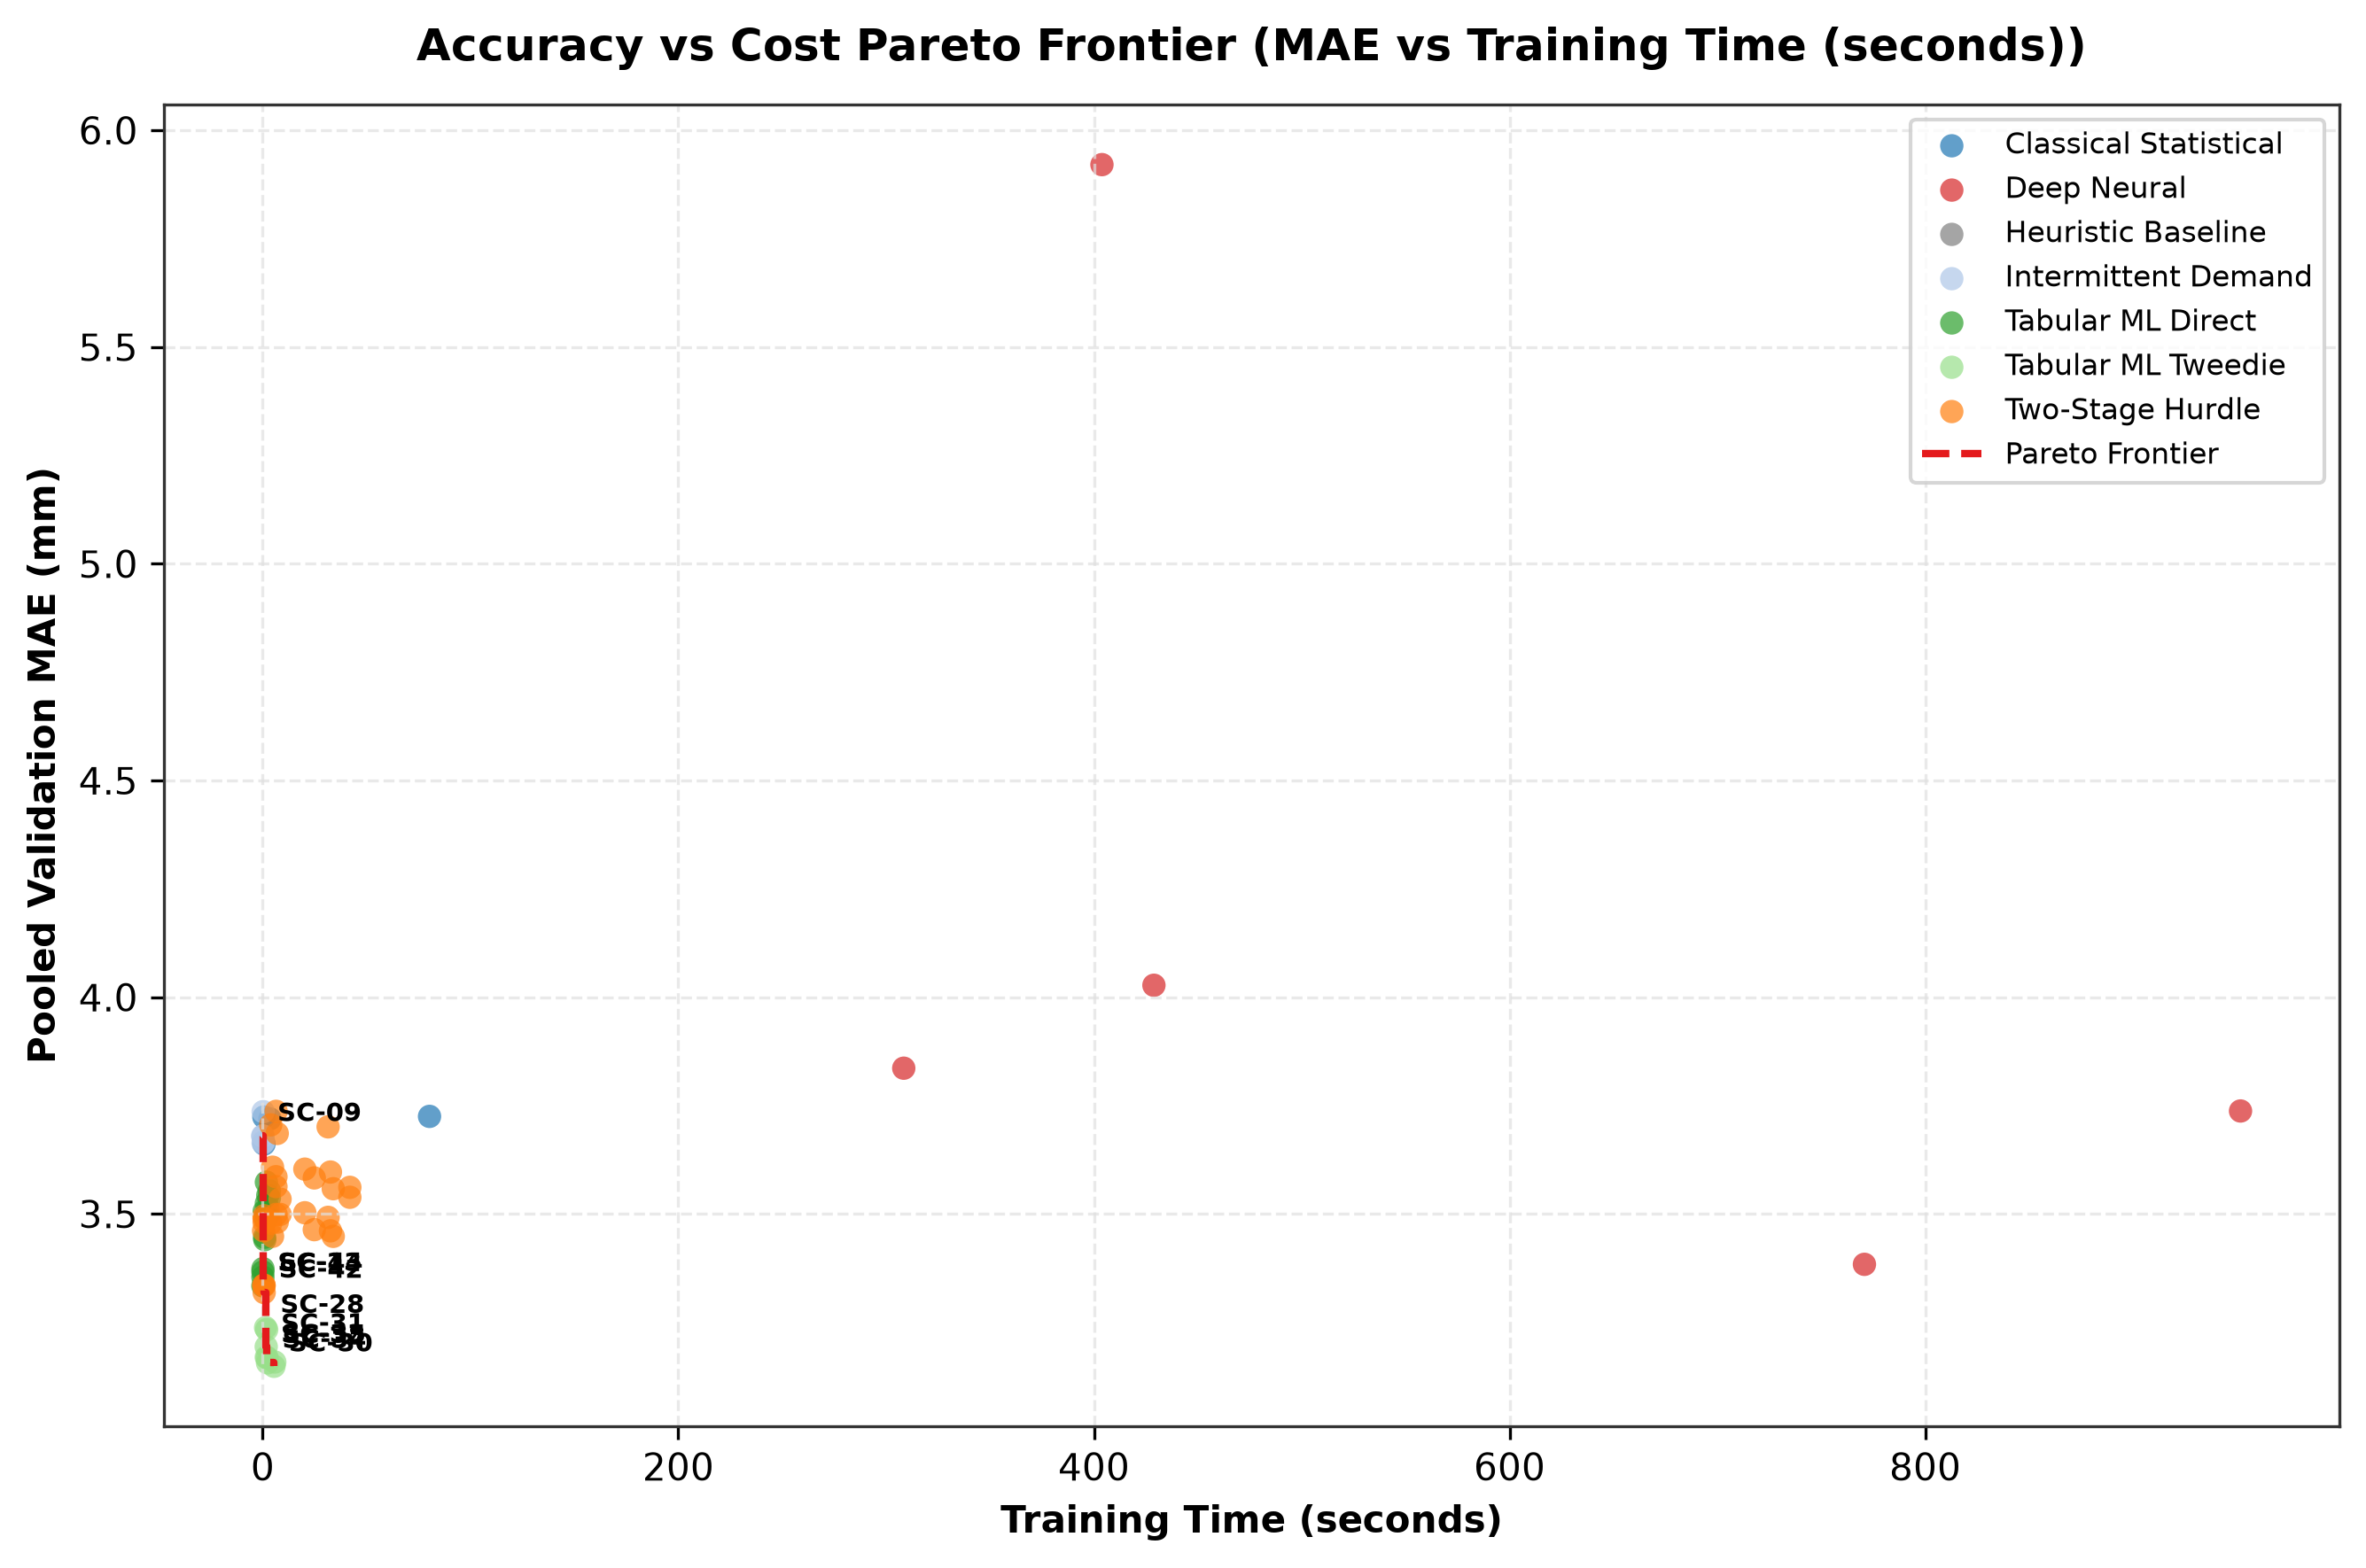

In [2]:
from src.analysis.loaders import load_all_validation_results
from src.analysis.resources import normalize_resource_metrics
from src.analysis.pareto import identify_pareto_frontier
from src.analysis.plotting import plot_pareto_frontiers

df_results = load_all_validation_results()
df_res = normalize_resource_metrics(df_results)

# 1. Pareto MAE vs Latency
pareto_lat = identify_pareto_frontier(df_res, x_col='latency_ms_per_origin', y_col='MAE')
print("PARETO FRONTIER: MAE vs Latency")
display(pareto_lat[['scenario_id', 'model', 'family', 'latency_ms_per_origin', 'MAE', 'RMSE']])
fig_lat = plot_pareto_frontiers(df_res, x_col='latency_ms_per_origin', y_col='MAE', save_name='fig07_pareto_latency.png')

# 2. Pareto MAE vs Training Time
pareto_train = identify_pareto_frontier(df_res, x_col='training_time_sec', y_col='MAE')
print("\nPARETO FRONTIER: MAE vs Training Time")
display(pareto_train[['scenario_id', 'model', 'family', 'training_time_sec', 'MAE', 'RMSE']])
fig_train = plot_pareto_frontiers(df_res, x_col='training_time_sec', y_col='MAE', save_name='fig07_pareto_training.png')
